# Adapting GeoCLIP to Fine-Grained Geolocation of Historical Swiss Photographs
### Interim results — internal note for team alignment

**Author:** Yijun Liu · **Status:** work in progress, 18 Nov 2026 · **Not the official report.**

All numbers below are recomputed in this notebook from the cached predictions in `$P2_DATA/results/`; nothing is copied by hand. Hyperparameters were selected on `val` only. The test splits were evaluated once per final configuration.

**Key findings so far**

1. **Fine-tuning works in-distribution.** On Test-in, A4 reaches a 34.2 km median and 41.3 % of images within 25 km. Zero-shot GeoCLIP (B1) gets 248.7 km and 10.8 %, and the strongest simple baseline, kNN (B2), gets 43.5 km and 32.8 %.
2. **Gains do not transfer to unseen areas.** In Ticino, every fine-tuned model falls to 3–8 % within 25 km. The zero-shot Swiss grid (A2) gets 23.9 %, so it generalises better than any fine-tuned variant.
3. **Fine-tuning helps at 25 km but hurts at 1 km.** Accuracy within 1 km drops from 1–2 % (B2, A2) to 0.3 % (A4). The gallery is not the bottleneck: a 1 km grid could get within 0.4 km. The model ranks the candidates wrongly.
4. **Reliability is useful in-distribution but over-confident on new regions.** On Test-in, the learned confidence beats raw `p1` at every threshold (AUROC 0.69 vs 0.63 at 25 km). On Ticino it is badly mis-calibrated (ECE 0.35).

## 1. Introduction

Archives hold many historical photographs without a recorded location. SMAPshot volunteers georeference them by hand, but this does not scale. Global image geolocation models such as GeoCLIP (Vivanco Cepeda et al., NeurIPS 2023) are trained at planet scale. On Swiss historical photographs they are too coarse, and they give no signal on when a prediction can be trusted.

**Research questions**

| | Question |
| --- | --- |
| **RQ1 — Adaptation** | Which adaptations of GeoCLIP (regional prior, Swiss candidate gallery, fine-tuning with Swiss negatives, distance-smoothed targets) improve fine-grained accuracy, and by how much each? |
| **RQ2 — Reliability** | Can we predict, from model outputs alone, the probability that a prediction is within $T \in \{1, 5, 25\}$ km, and is that probability calibrated? |
| **RQ3 — Generalisation** | Do the gains hold on a held-out city (Bern) and a held-out canton (Ticino) that never appear in training? |

In [1]:
import json, os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "report" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ.setdefault("P2_DATA", "/rcp-scratch/students/yijliu/ml-project2/data")

from lib.geo import haversine_km
from lib.paths import META, RESULTS

PREDS, METRICS, FIGS = RESULTS / "preds", RESULTS / "metrics", ROOT / "report" / "figures"
SPLITS = ["val", "test_in", "test_city", "test_region"]
SPLIT_LABEL = {"val": "val", "test_in": "Test-in", "test_city": "Test-city (Bern)", "test_region": "Test-region (Ticino)"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 1)

## 2. Data and benchmark

**Source.** 355,281 validated SMAPshot images, retrieved through the public API. The coordinate is the **camera position**, not the depicted scene.

**Cleaning.**
- Images more than 5 km outside the Swiss border are dropped (31,138).
- Nadir views (40,531) are excluded from the main experiments.
- Thumbnails are downloaded at 512 px, and frozen CLIP ViT-L/14 features (768-d) are cached once for 308,672 images.

**Spatially disjoint split** (seed 0, fixed before any image was downloaded):
- *Test-region* is the whole canton of Ticino. It differs from the training area in language and topography (south of the Alps).
- *Test-city* covers everything within 10 km of Bern city centre.
- A buffer around both held-out areas is used neither for training nor for testing.
- The remaining images are grouped into 10 km × 10 km LV95 blocks. Whole blocks are assigned to train, val and Test-in at roughly 70/10/20, so no block is split across sets and nearby near-duplicates cannot leak between them.

In [2]:
splits = pd.read_csv(ROOT / "data/splits/main.csv.gz")
meta = pd.read_parquet(META / "smapshot.parquet", columns=["id", "latitude", "longitude", "view_type"])
truth = splits.merge(meta, on="id")
truth = truth[~truth.split.str.startswith("nadir_")]
truth["view_type"] = truth.view_type.fillna("unknown")

order = ["train", "val", "test_in", "test_city", "test_region", "buffer", "outside"]
tab = (truth.groupby(["split", "view_type"]).size().unstack(fill_value=0)
       .reindex(order).rename(index=SPLIT_LABEL))
tab["total"] = tab.sum(axis=1)
tab

view_type,highOblique,lowOblique,terrestrial,unknown,total
split,,,,,
train,37093,76797,58425,4223,176538
val,7497,12739,8662,634,29532
Test-in,11462,19388,15446,1313,47609
Test-city (Bern),928,978,1455,17,3378
Test-region (Ticino),1423,2585,8994,38,13040
buffer,1994,3949,7488,84,13515
outside,103,30493,529,13,31138


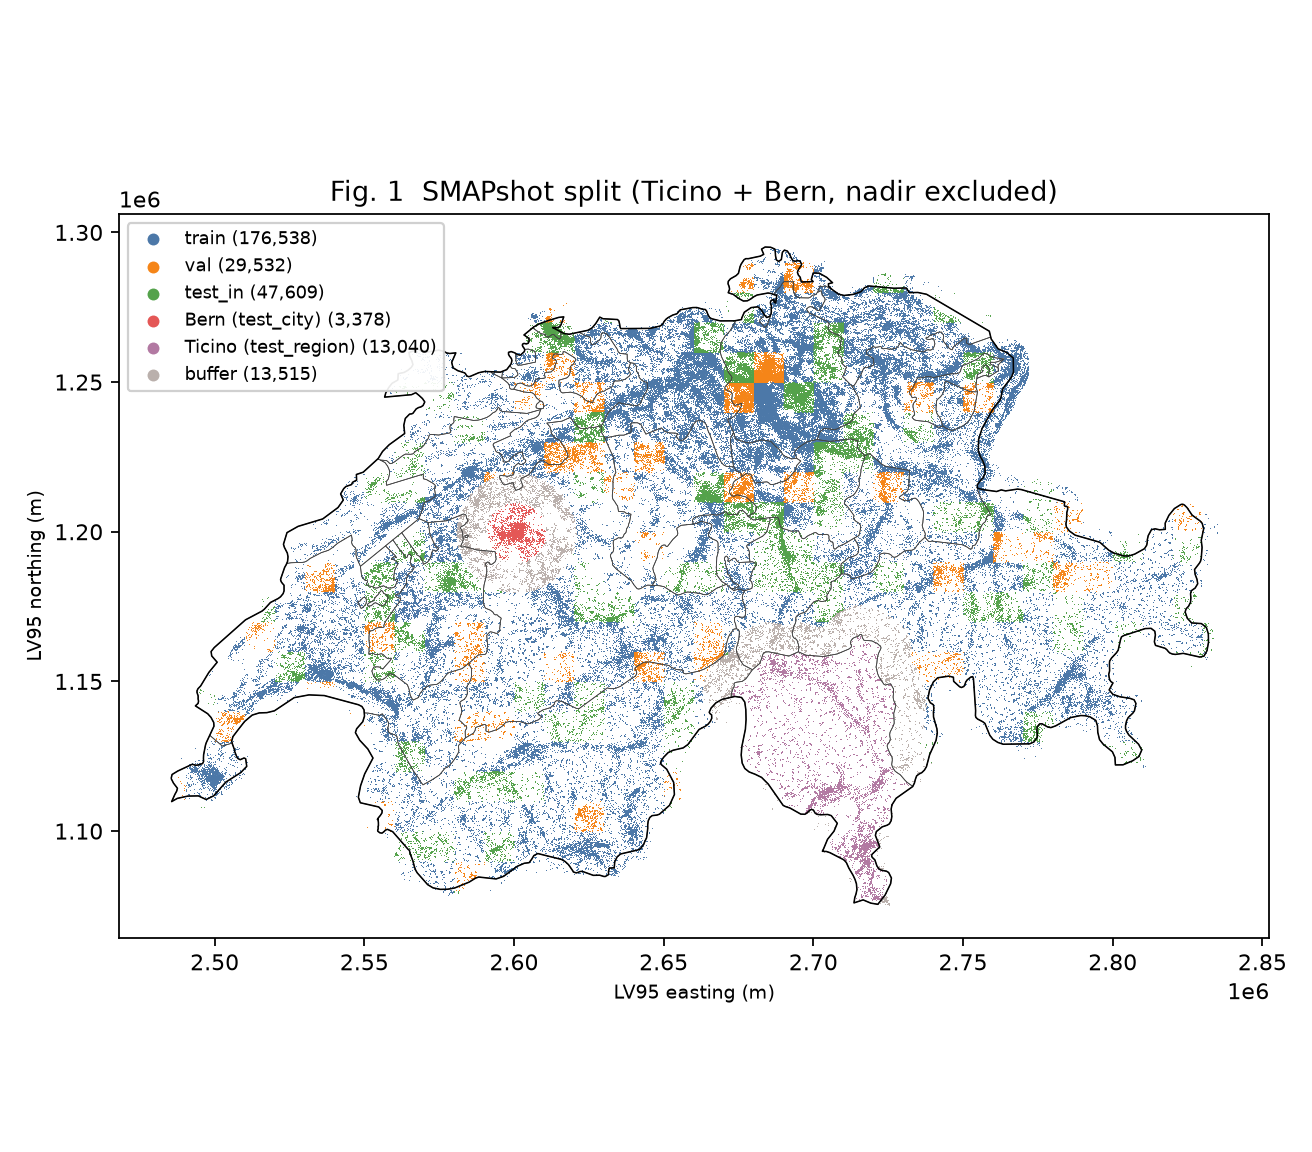

In [3]:
display(Image(filename=str(FIGS / "fig1_split_map.png"), width=720))

*Figure 1. Spatially disjoint split: train/val/Test-in by 10 km blocks, held-out city (Bern) and canton (Ticino), and the buffer zones between them.*

**Metrics.** Haversine error in km, reported as the median and as accuracy within 1 / 5 / 25 km. The 95 % CIs of the median are obtained by bootstrapping whole spatial blocks rather than individual images.

## 3. Methods

All methods share the same frozen CLIP features. They differ in what is scored, in the candidate gallery, and in what is trained.

| ID | Method | Gallery | Trained parameters |
| --- | --- | --- | --- |
| **B0** | Constant prediction: the median train coordinate | — | — |
| **B1** | GeoCLIP zero-shot | global MP-16 (100k points) | — |
| **B2** | kNN retrieval: coordinate of the top-1 CLIP neighbour in train | train images | — |
| **A1** | B1 + regional prior $s - \lambda\,U(g)$ that penalises points outside Switzerland ($\lambda=30$, scale 25 km, chosen on val) | MP-16 | — |
| **A2 (= B3)** | GeoCLIP with a Swiss 1 km grid | 48,554 Swiss grid points | — |
| **A3a** | Fine-tune the image MLP with global negatives | 1 km grid | image MLP |
| **A3b** | A3a with Swiss-grid negatives | 1 km grid | image MLP |
| **A3c** | A3b plus the location encoder | 1 km grid | MLP + location encoder |
| **A4** | A3c with a haversine-smoothed soft target ($\tau = 5$ km), in the spirit of PIGEON | 1 km grid | MLP + location encoder |

Fine-tuning runs on 176k non-nadir train images for 15 epochs with batch size 512 and 4,096 negatives. The checkpoint is selected by median error on a 5k val subset. A4 is repeated with three seeds.

**Reliability model (RQ2).** For each prediction of A4 (seed 0), a gradient-boosted classifier predicts $P(e \le T)$ from model outputs only. Its inputs are:
- the top-1 probability `p1`, the logit margin, and the entropy of the top-20 scores;
- the spatial spread of the top-20 candidates;
- the kNN similarity and the A4–kNN disagreement;
- one-hot `view_type`.

The classifier is fitted on **val only**: depth is selected by `GroupKFold` over spatial blocks, followed by isotonic calibration. The baseline applies isotonic regression to `p1` alone.

## 4. Results

### 4.1 Main comparison across the three test settings

In [4]:
RUNS = {"B0": "B0", "B1": "B1", "B2": "B2", "A1": "A1", "A2 (=B3)": "B3",
        "A3a": "A3a", "A3b": "A3b", "A3c": "A3c", "A4": "A4_tau5"}

def load_errors(run):
    p = pd.read_parquet(PREDS / f"{run}.parquet")
    p = p[p.split.isin(SPLITS)].merge(truth[["id", "latitude", "longitude", "view_type", "block"]], on="id")
    p["err_km"] = haversine_km(p.latitude.values, p.longitude.values, p.lat_pred.values, p.lon_pred.values)
    return p

errs = {name: load_errors(run) for name, run in RUNS.items()}
common = set.intersection(*(set(e.id) for e in errs.values()))
errs = {k: v[v.id.isin(common)].reset_index(drop=True) for k, v in errs.items()}
print(f"evaluated on the {len(common):,} images predicted by every method")

def summary(e):
    x = e.err_km.values
    return pd.Series({"median km": np.median(x), "≤1 km %": (x <= 1).mean() * 100,
                      "≤5 km %": (x <= 5).mean() * 100, "≤25 km %": (x <= 25).mean() * 100})

rows = []
for name, e in errs.items():
    for split, g in e.groupby("split"):
        rows.append({"method": name, "split": SPLIT_LABEL[split], **summary(g)})
res = pd.DataFrame(rows)
main = res.pivot(index="method", columns="split", values=["median km", "≤25 km %"]).reindex(list(RUNS))
main = main.reindex(columns=[SPLIT_LABEL[s] for s in SPLITS], level=1)
main.style.format("{:.1f}").set_caption("Table 1. Median error (km, lower is better) and accuracy within 25 km (%, higher is better).")

evaluated on the 93,538 images predicted by every method


In [5]:
fine = res[res.split == "Test-in"].set_index("method").drop(columns="split").reindex(list(RUNS))
fine.style.format("{:.1f}").set_caption("Table 2. Fine-grained accuracy on Test-in.")

,median km,≤1 km %,≤5 km %,≤25 km %
method,,,,
B0,60.6,0.0,0.0,12.1
B1,248.7,0.7,2.6,10.8
B2,43.5,2.0,7.3,32.8
A1,70.9,1.5,4.6,17.8
A2 (=B3),64.1,1.1,4.3,19.2
A3a,38.5,0.7,8.5,37.9
A3b,35.2,0.5,6.3,40.2
A3c,36.3,0.4,6.8,39.2
A4,34.2,0.3,5.7,41.3


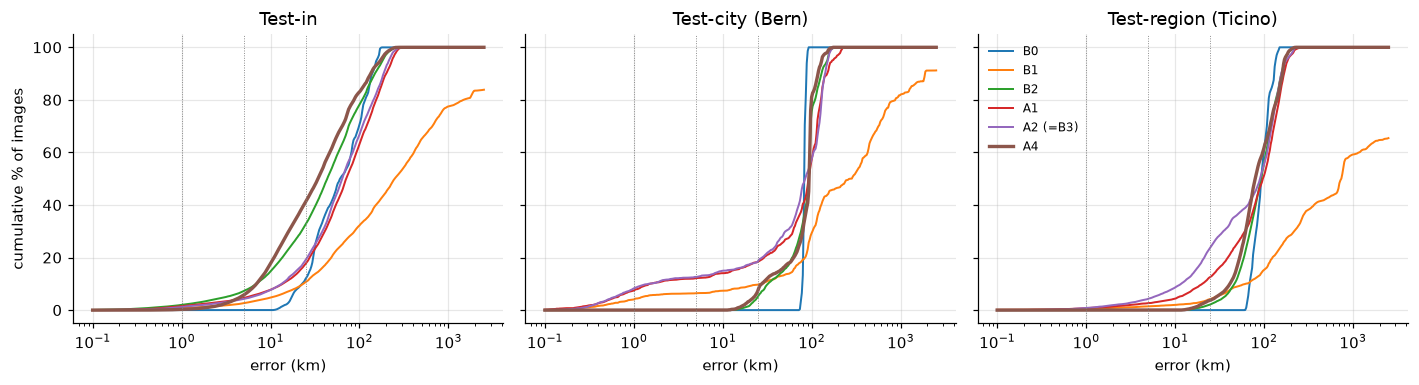

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
show = ["B0", "B1", "B2", "A1", "A2 (=B3)", "A4"]
xs = np.logspace(-1, 3.4, 400)
for ax, split in zip(axes, ["test_in", "test_city", "test_region"]):
    for name in show:
        x = np.sort(errs[name].loc[errs[name].split == split, "err_km"].values)
        ax.plot(xs, np.searchsorted(x, xs, side="right") / len(x) * 100, label=name,
                lw=2.2 if name == "A4" else 1.3)
    for t in (1, 5, 25):
        ax.axvline(t, color="grey", lw=0.6, ls=":")
    ax.set(xscale="log", title=SPLIT_LABEL[split], xlabel="error (km)")
axes[0].set_ylabel("cumulative % of images")
axes[-1].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(FIGS / "error_cdf.png", dpi=200, bbox_inches="tight"); plt.show()

*Figure 2. Cumulative error distribution on the three test settings (log x-axis; dotted lines mark 1 / 5 / 25 km).*

**Observations.**
- **Zero-shot GeoCLIP is unusable at Swiss scale.** B1 has a median error of ~250 km on Test-in and is worse than predicting a constant point (B0, 60.6 km), because many predictions land outside Switzerland.
- **Restricting the output space removes most of that error.** The regional prior (A1) and the Swiss grid (A2) bring the median down to 64–71 km.
- **Fine-tuning gives the largest gain.** On Test-in, A4 beats B2 by 9.3 km in median error and 8.5 points in accuracy within 25 km.
- **On Bern and Ticino, the ranking reverses.** kNN (B2) has no training images nearby and drops to 2–5 % within 25 km. All fine-tuned models also collapse (3–14 %). A2, which uses no Swiss training at all, is the best method on Ticino (23.9 % within 25 km) and close to the best on Bern (18.8 %). Fine-tuning appears to specialise the image encoder to the training regions instead of learning transferable cues.
- **The Bern medians are uninformative.** All methods sit at 82–94 km, which is no better than the constant prediction. Bern is a small area (radius 10 km) whose images resemble those of many other Swiss towns.

### 4.2 Ablation (RQ1): what each adaptation contributes

In [7]:
val = res[res.split == "val"].set_index("method").drop(columns="split").reindex(list(RUNS))
val.style.format("{:.1f}").set_caption("Table 3. Ablation on val, one change per row.")

,median km,≤1 km %,≤5 km %,≤25 km %
method,,,,
B0,59.5,0.0,0.5,10.9
B1,247.8,2.2,5.3,14.6
B2,37.6,2.7,11.4,38.5
A1,67.5,3.4,8.3,24.1
A2 (=B3),62.1,3.0,7.4,20.8
A3a,33.4,1.5,10.1,42.5
A3b,28.9,1.2,10.9,46.2
A3c,29.9,1.3,8.8,45.4
A4,27.7,0.4,9.7,47.3


In [8]:
ms = json.load(open(METRICS / "A4_tau5_multiseed.json"))["aggregate"]
seeds = pd.DataFrame({SPLIT_LABEL[s]: {"median km (mean ± sd)": f"{ms[s]['median_km_mean']:.1f} ± {ms[s]['median_km_stdev']:.1f}",
                                       "≤25 km % (mean)": f"{ms[s]['acc@25km_mean']:.1f}"} for s in SPLITS}).T
seeds.style.set_caption("Table 4. A4 over three seeds (1 km grid inference).")

,median km (mean ± sd),≤25 km % (mean)
val,26.6 ± 1.0,48.4
Test-in,32.0 ± 1.9,43.2
Test-city (Bern),93.3 ± 0.6,8.1
Test-region (Ticino),79.8 ± 0.9,3.7


In [9]:
oracle = json.load(open(METRICS / "oracle_val.json"))
a2_med = val.loc["A2 (=B3)", "median km"]
pd.DataFrame({"gallery": ["Swiss 1 km grid", "unique train coordinates"],
              "oracle median km": [oracle["grid_1km"]["median_km"], oracle["train_unique"]["median_km"]],
              "points": [oracle["grid_1km"]["n_gallery"], oracle["train_unique"]["n_gallery"]]}
            ).style.format({"oracle median km": "{:.2f}", "points": "{:,}"}).hide(axis="index").set_caption(
    f"Table 5. Gallery oracle on val: error of the gallery point closest to the ground truth. Actual A2 median: {a2_med:.1f} km.")

gallery,oracle median km,points
Swiss 1 km grid,0.39,"48,554"
unique train coordinates,2.07,"156,255"


**Observations.**
- **Swiss negatives give the largest step** (A3a → A3b: 33.4 → 28.9 km on val). With only global negatives, the model mostly learns to separate Switzerland from the rest of the world. With negatives drawn from the Swiss grid, it must also tell Swiss locations apart.
- **Training the location encoder adds nothing on its own** (A3c, 29.9 km).
- **The soft target recovers and slightly improves the result** (A4, 27.7 km / 47.3 %). Across three seeds A4 is stable (Test-in 32.0 ± 1.9 km), so differences of about 1 km between variants are within seed noise.
- **Every fine-tuned variant loses accuracy within 1 km.** Contrastive training with a 1 km noise σ and a 5 km soft target smooths the score surface, which trades exact hits for fewer large errors.
- **The bottleneck is ranking, not gallery density.** The 1 km grid contains a point within 0.39 km of the truth for half of the val images, while the actual A2 median is 62 km.

### 4.3 Error by view type

In [10]:
vt = pd.concat({name: errs[name][errs[name].split == "test_in"].groupby("view_type").apply(summary, include_groups=False)
                for name in ["B2", "A4"]}, names=["method"])
vt["n"] = errs["A4"][errs["A4"].split == "test_in"].view_type.value_counts().reindex(vt.index.get_level_values(1)).values
vt.style.format({c: "{:.1f}" for c in vt.columns if c != "n"} | {"n": "{:,}"}).set_caption("Table 6. Test-in by view type.")

**Observations.** Low-oblique aerial views are the easiest (A4: 27.2 km, 47.3 % within 25 km). Terrestrial photographs are the hardest (44.3 km, 35.3 %), probably because they show street-level content with few distinctive landmarks. A4 improves over kNN on every view type at 25 km. Terrestrial images make up 69 % of Ticino (8,994 / 13,040) but only 33 % of train, so part of the drop on Test-region is also a shift in view type.

### 4.4 Reliability (RQ2)

In [11]:
rel = json.load(open(METRICS / "reliability.json"))["test"]
rows = []
for split, by_t in rel.items():
    for T, r in by_t.items():
        rows.append({"split": SPLIT_LABEL[split], "T (km)": int(T), "positive rate %": r["model"]["pos_rate"] * 100,
                     "AUROC model": r["model"]["auroc"], "AUROC p1": r["p1"]["auroc"],
                     "ECE model": r["model"]["ece"], "ECE p1": r["p1"]["ece"],
                     "Brier model": r["model"]["brier"], "Brier p1": r["p1"]["brier"]})
rel_df = pd.DataFrame(rows).set_index(["split", "T (km)"])
fmt = {c: "{:.3f}" for c in rel_df.columns} | {"positive rate %": "{:.1f}"}
rel_df.style.format(fmt, na_rep="—").set_caption(
    "Table 7. Reliability on the test splits (fitted on val only). AUROC is undefined when there are no positives.")

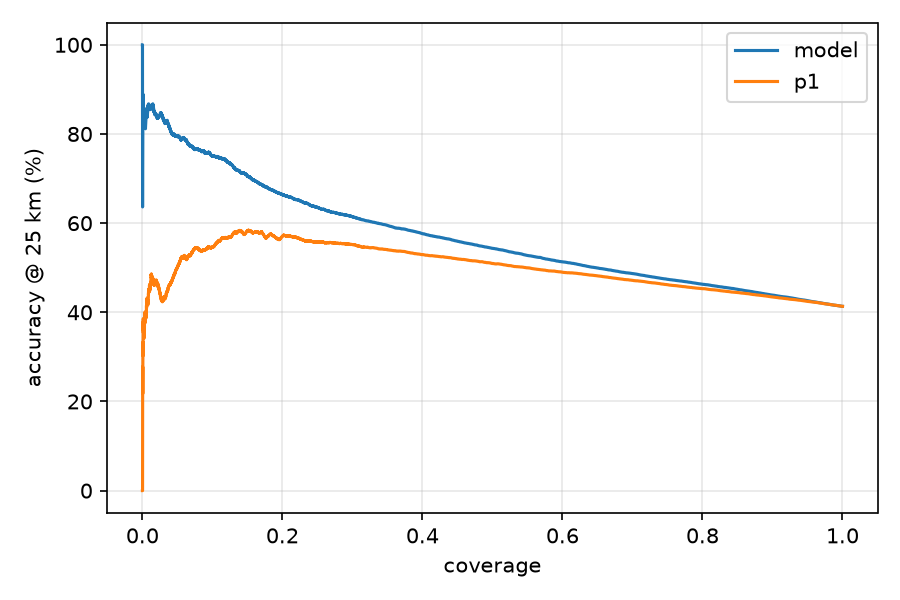

In [12]:
display(Image(filename=str(FIGS / "risk_coverage.png"), width=480))

*Figure 3. Risk–coverage on Test-in at T = 25 km: accuracy among the most confident x % of images, for the learned model and for p1.*

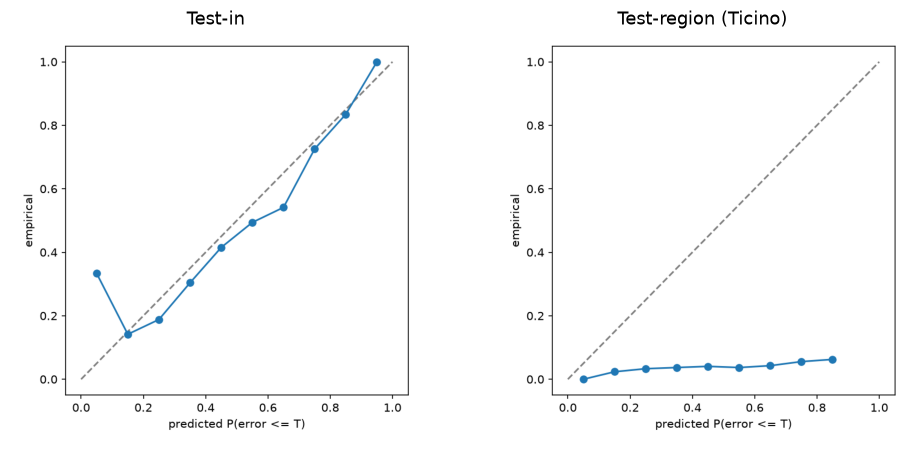

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, f, title in zip(axes, ["calibration_test_in.png", "calibration_test_region.png"], ["Test-in", "Test-region (Ticino)"]):
    ax.imshow(plt.imread(FIGS / f)); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

*Figure 4. Reliability diagrams at T = 25 km. The diagonal is perfect calibration.*

**Observations.**
- **In-distribution, the learned model ranks better than `p1` at every threshold** (Test-in AUROC 0.75 / 0.71 / 0.69 vs 0.71 / 0.68 / 0.63 at 1 / 5 / 25 km).
- **Abstaining on uncertain images pays off.** Keeping only the most confident ~10 % of Test-in images raises accuracy within 25 km from 41 % to about 75 % (Figure 3).
- **Calibration on Test-in is good** (ECE 0.05, Figure 4 left).
- **On unseen regions, the estimator is over-confident.** It was fitted on val, where 47 % of images are within 25 km. In Ticino only 3.8 % are, so predicted probabilities stay far above the observed rate (ECE 0.35, Figure 4 right).
- **Ranking also breaks down on unseen regions.** AUROC in Ticino is 0.52, and on Bern it falls below 0.5. The features describe agreement with the training distribution, which is exactly what is missing in a new region.
- **AUROC at 1 and 5 km is undefined on Bern and Ticino**, because no prediction there is that close.

## 5. Summary and open points

| RQ | Answer so far |
| --- | --- |
| RQ1 | Yes, in-distribution. Swiss negatives give the largest gain, and the soft target adds a little. A4 is the best model on Test-in. |
| RQ2 | Partly. The learned confidence beats `p1` and is calibrated on Test-in, but not on unseen regions. |
| RQ3 | No, for the fine-tuned models. On Ticino, zero-shot GeoCLIP with a Swiss grid outperforms every fine-tuned variant. |

**Points to discuss with the team**
1. Should Test-region be the headline column? It is where the methods differ most, and where the most interesting negative result sits.
2. Planned next experiments:
   - mix the zero-shot (A2) and fine-tuned (A4) scores, or fine-tune with stronger regularisation, to keep the zero-shot robustness;
   - re-estimate the reliability base rate per region (for example with label-free prior adjustment);
   - report bootstrap CIs in the final tables.
3. Labels are camera positions, not scene positions. For high-oblique views the two can be several km apart, which caps accuracy within 1 km.